# PH5720 — Problem Set 5
**Department of Physics | IIT Madras | January–May 2025**


## Question 1

Write a program to calculate the differentiation of the $\sin(x)$ function using the forward differentiation method.

Plot the numerical derivatives and compare them with the analytical derivative.

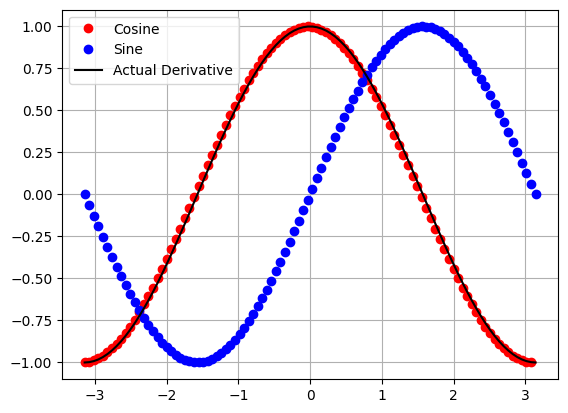

In [1]:
import numpy as np
import matplotlib.pyplot as plt
def f(x):
    return np.sin(x)
X,h = np.linspace(-np.pi, np.pi, 100,retstep=True)
Y=f(X)
X1=[]
Y1=[]
for i in range(len(X)-1):
    y1=(Y[i+1]-Y[i])/(h)
    x1=X[i]
    Y1.append(y1)
    X1.append(x1)
    
plt.plot(X1,Y1,'ro',label='Cosine')
plt.plot(X,Y,'bo',label='Sine')
plt.plot(X,np.cos(X),'k',label='Actual Derivative')
plt.legend()
plt.grid(True)
plt.show()

## Question 2

Do the same, but use the backward difference method.

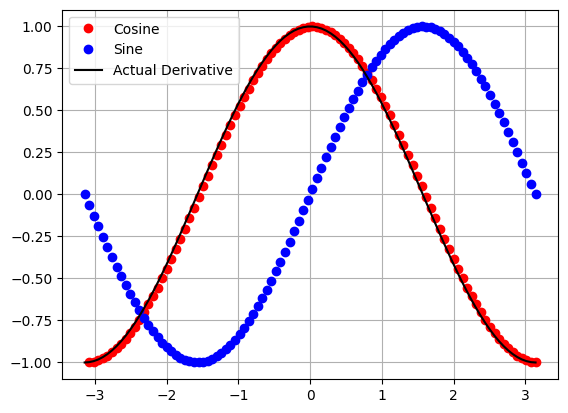

In [2]:
import numpy as np
import matplotlib.pyplot as plt
def f(x):
    return np.sin(x)
X,h = np.linspace(-np.pi, np.pi, 100,retstep=True)
Y=f(X)
X1=[]
Y1=[]
for i in range(1,len(X)):
    y1=(Y[i]-Y[i-1])/(h)
    x1=X[i]
    Y1.append(y1)
    X1.append(x1)
    
plt.plot(X1,Y1,'ro',label='Cosine')
plt.plot(X,Y,'bo',label='Sine')
plt.plot(X,np.cos(X),'k',label='Actual Derivative')
plt.legend()
plt.grid(True)
plt.show()

## Question 3

Repeat Problem 1, but use the central difference method.

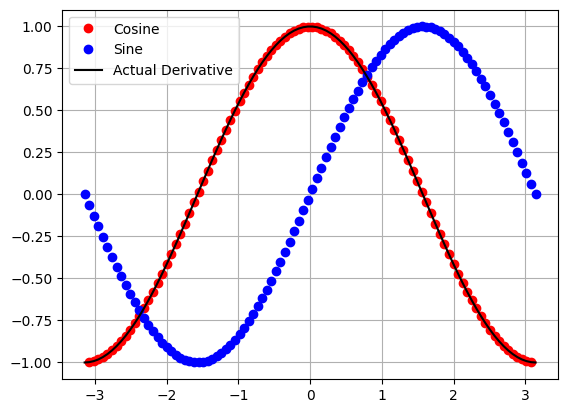

In [3]:
import numpy as np
import matplotlib.pyplot as plt
def f(x):
    return np.sin(x)
X,h = np.linspace(-np.pi, np.pi, 100,retstep=True)
Y=f(X)
X1=[]
Y1=[]
for i in range(1,(len(X)-1)):
    y1=(Y[i+1]-Y[i-1])/(2*h)
    x1=X[i]
    Y1.append(y1)
    X1.append(x1)
    
plt.plot(X1,Y1,'ro',label='Cosine')
plt.plot(X,Y,'bo',label='Sine')
plt.plot(X,np.cos(X),'k',label='Actual Derivative')
plt.legend()
plt.grid(True)
plt.show()

## Question 4

Use the functions for (a) forward difference, (b) backward difference and (c) central difference to evaluate the first derivative of

$$
f(x)=e^{\sin(2x)}
$$

for different step sizes $h$, for a fixed $x$.

You may start with a step size of $h=0.1$ and go down to a size of $h=10^{-15}$.

Make a log-log plot of $h$ versus the relative error between the calculated and the analytical expression for the derivative, and extract the slope of the linear regions for both the methods.

What is the slope and what does it say about the error? Comment on the observed behaviour of the errors below.

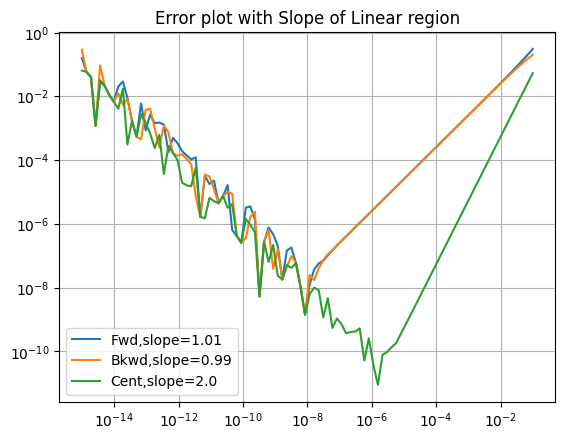

In [17]:
m=0.5
import numpy as np
def f(x):
    return np.exp(np.sin(2*x))
def f1(x):
    return 2*f(x)*np.cos(2*x)
H=np.logspace(-15,-1,100)
def fwd(x,h):
    return (f(x+h)-f(x))/h
def bkwd(x,h):
    return (f(x)-f(x-h))/h
def cent(x,h):
    return (f(x+h)-f(x-h))/(2*h)
err_fwd=[abs(fwd(m,h)-f1(m)) for h in H]
err_bkwd=[abs(bkwd(m,h)-f1(m)) for h in H]
err_cent=[abs(cent(m,h)-f1(m)) for h in H]



H1=np.logspace(-5,-1,50)
err_fwd_1=[abs(fwd(m,h)-f1(m)) for h in H1]
err_bkwd_1=[abs(bkwd(m,h)-f1(m)) for h in H1]
err_cent_1=[abs(cent(m,h)-f1(m)) for h in H1]

slope1,intercept1=np.polyfit(np.log(H1),np.log(err_fwd_1),1)
slope2,intercept2=np.polyfit(np.log(H1),np.log(err_bkwd_1),1)
slope3,intercept3=np.polyfit(np.log(H1),np.log(err_cent_1),1)
#slope1_1=np.log(err_fwd[-1]/err_fwd[-8])/(np.log(H[-1]/H[-8]))


plt.loglog(H,err_fwd,label=f'Fwd,slope={round(slope1,2)}')
plt.loglog(H,err_bkwd,label=f'Bkwd,slope={round(slope2,2)}')
plt.loglog(H,err_cent,label=f'Cent,slope={round(slope3,2)}')
plt.title('Error plot with Slope of Linear region')
plt.grid(True)
plt.legend()
plt.show()


## Question 5

Write a Python function to evaluate the second derivative of

$$
f(x)=e^{\sin(2x)}.
$$

Make a log-log plot of $h$ versus the relative error between the calculated and the analytical expression for the derivative, and extract the slopes of the linear regions from both and explain the behaviour below.

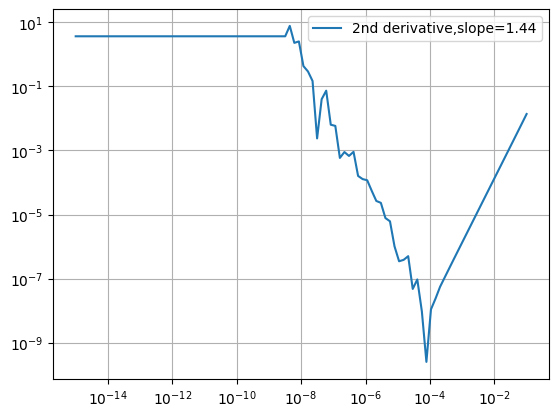

In [19]:
m=float(input('Enter a value for x'))
import numpy as np
def f(x):
    return np.exp(np.sin(2*x))
def f1(x):
    return 2*f(x)*np.cos(2*x)
def f2(x):
    return 2*(f1(x)*np.cos(2*x)-f(x)*np.sin(2*x)*2)
H=np.logspace(-15,-1,100)
def cent(x,h):
    return (f(x+h)+f(x-h)-2*f(x))/(h**2)  #2nd order derivative 


err_cent=[abs(cent(m,h)-f2(m)) for h in H]

H1=np.logspace(-5,-1,50)
err_cent_1=[abs(cent(m,h)-f2(m)) for h in H1]
slope1,k=np.polyfit(np.log(H1),np.log(err_cent_1),1)
plt.loglog(H,err_cent,label=f'2nd derivative,slope={round(slope1,2)}')
plt.grid(True)
plt.legend()
plt.show()


## Question 6

Numerically estimate the energy of a particle in a box with a given wave function (time-independent).

eigen value from D.E=4.38649054335228,numerically calculated value4.386490844928603


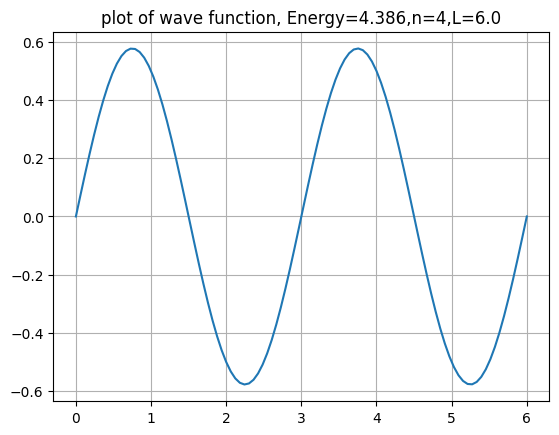

In [23]:
n=int(input('Enter a value for n'))
L=float(input('Enter a value for L(length of of box'))
def f(x):
    return ((2/L)**0.5)*np.sin(n*x*np.pi/L)

def cent(x,h):
    return (f(x+h)+f(x-h)-2*f(x))/(h**2)
point=L/3
if f(point)<0.01:
    point=point*np.exp(-1)
x=np.linspace(0,L,100)
energy_eigenvalue=(-cent(point,0.00001)/f(point))
print(f'eigen value from D.E={energy_eigenvalue},numerically calculated value{(np.pi*n/L)**2}')

plt.plot(x,f(x))
plt.title(f'plot of wave function, Energy={round(energy_eigenvalue,3)},n={n},L={L}')
#plt.legend()
plt.grid(True)
plt.show()